# Smogon Usage Stats (Complete): how to get data out

The Lite dataset keeps the most played formats at one rating cutoff. The Complete one keeps everything [smogon.com/stats](https://www.smogon.com/stats/) publishes: every format, every cutoff, plus EV spreads, teammates, checks and counters, leads and team styles. It is too big to load whole, so this notebook is about asking for a slice.

The reading is done by [`smogon-stats`](https://pypi.org/project/smogon-stats/), which downloads only the files a query needs. No Kaggle account is required.

In [1]:
%pip install -q smogon-stats

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import polars as pl

import smogon_stats as ss

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update(
    {
        "figure.figsize": (10, 4.5),
        "figure.dpi": 110,
        "axes.prop_cycle": plt.cycler(color=SERIES_COLORS),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e4e3df",
        "axes.titlelocation": "left",
        "axes.titleweight": "bold",
        "lines.linewidth": 2,
    }
)
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_hide_column_data_types(True);

## How it is organised

There is one Kaggle dataset per year (`smogon-usage-stats-complete-2019`, ...). Each holds `pokemon.parquet`, `formats.parquet`, and one folder per table with one file per month (`spreads/2019-06.parquet`). `files.parquet` lists what is there.

In [3]:
files_2019 = ss.load("files", years=[2019]).collect()
files_2019.group_by("table").agg(
    pl.len().alias("months"), pl.col("month").min().alias("first"), pl.col("month").max().alias("last")
).sort("table")

table,months,first,last
"""abilities""",12,"""2019-01""","""2019-12"""
"""checks_counters""",12,"""2019-01""","""2019-12"""
"""cutoffs""",12,"""2019-01""","""2019-12"""
"""happiness""",12,"""2019-01""","""2019-12"""
"""items""",12,"""2019-01""","""2019-12"""
"""leads""",12,"""2019-01""","""2019-12"""
"""metagame_styles""",12,"""2019-01""","""2019-12"""
"""moves""",12,"""2019-01""","""2019-12"""
"""movesets""",12,"""2019-01""","""2019-12"""
"""spreads""",12,"""2019-01""","""2019-12"""


You do not have to care about that layout: `ss.load(table, years=...)` or `ss.load(table, months=[...])` finds the files and returns one LazyFrame. `formats=` and `cutoffs=` add filters. Every table shares the keys `month`, `format`, `cutoff` and, where it applies, `pokemon_id`.

`formats` is the table to start from. It says what each format name stands for, and here it shows how much the Lite leaves out in a single month.

In [4]:
formats = ss.load("formats", years=range(2015, 2021)).collect()
pokemon = ss.load("pokemon", years=[2020]).collect()

june_2019 = formats.filter(pl.col("month") == "2019-06")
print(f"2019-06: {june_2019.height} formats, {june_2019['lite_series'].is_not_null().sum()} of them in the Lite")
not_in_lite = june_2019.filter(pl.col("lite_series").is_null() & ~pl.col("format").str.contains("-mono"))
not_in_lite.sort("battles", descending=True).select("format", "gen", "family", "battles", "standard_cutoff").head(8)

2019-06: 62 formats, 15 of them in the Lite


format,gen,family,battles,standard_cutoff
"""gen71v1""",7,"""1v1""",456033,1630
"""gen7pu""",7,"""pu""",137465,1630
"""gen7battlespotsingles""",7,"""battlespotsingles""",111834,1630
"""gen7balancedhackmons""",7,"""balancedhackmons""",97060,1630
"""gen7lc""",7,"""lc""",55584,1630
"""gen7inheritance""",7,"""inheritance""",36035,1630
"""gen7doublesubers""",7,"""doublesubers""",33895,1630
"""gen7zu""",7,"""zu""",33181,1630


## One table over several years

Little Cup is not in the Lite. Its name changes with the generation (`lc`, `gen7lc`, `gen8lc`), and older generations keep their own ladder with a handful of battles. `formats.family` groups them; keeping the most played one each month gives a continuous series.

Two things to filter on in `formats` before joining: `is_special_month` (half-month and DLC folders of 2020, which repeat battles of the full month) and the cutoff you want, here `standard_cutoff`.

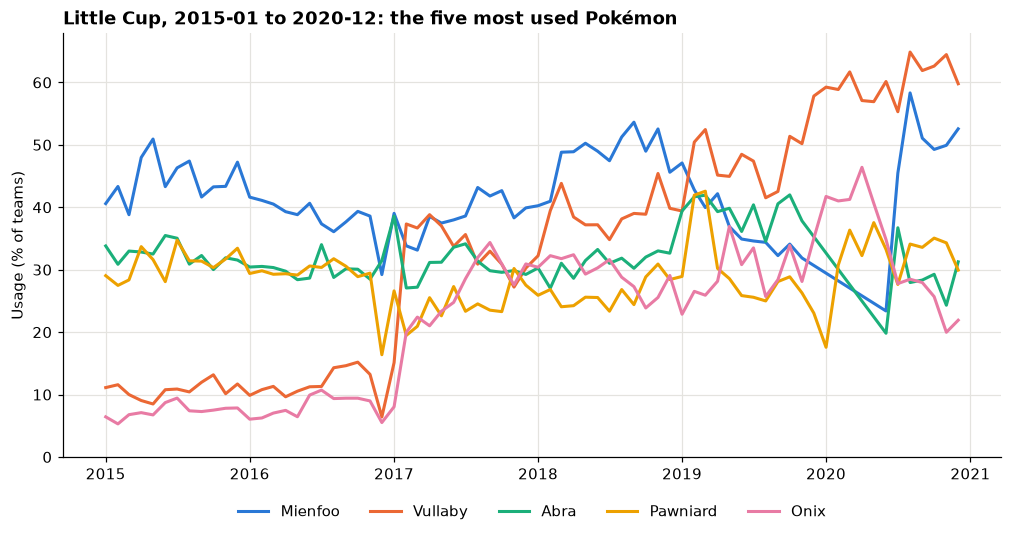

In [5]:
little_cup = (
    formats.filter((pl.col("family") == "lc") & ~pl.col("is_special_month"))
    .sort("battles", descending=True)
    .unique("month", keep="first", maintain_order=True)
    .select("month", "format", pl.col("standard_cutoff").alias("cutoff"))
)

lc_usage = (
    ss.load("usage", years=range(2015, 2021), formats=little_cup["format"].unique().to_list())
    .join(little_cup.lazy(), on=["month", "format", "cutoff"])
    .join(pokemon.lazy().select("pokemon_id", "name"), on="pokemon_id")
    .with_columns(pl.col("month").str.to_date("%Y-%m").alias("month_start"))
    .sort("month")
    .collect()
)
lc_months = lc_usage["month"].n_unique()
lc_leaders = (
    lc_usage.group_by("name")
    .agg((pl.col("usage_pct").sum() / lc_months).alias("mean_usage"))
    .sort("mean_usage", "name", descending=[True, False])
    .head(5)["name"]
)

fig, ax = plt.subplots(figsize=(11, 5))
for name in lc_leaders:
    one_pokemon = lc_usage.filter(pl.col("name") == name)
    ax.plot(one_pokemon["month_start"], one_pokemon["usage_pct"], label=name)
ax.set_title(f"Little Cup, {lc_usage['month'].min()} to {lc_usage['month'].max()}: the five most used Pokémon")
ax.set_ylabel("Usage (% of teams)")
ax.set_ylim(0)
ax.legend(ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.show()

## What the cutoff changes

Each file exists at four cutoffs: 0, 1500, and two higher ones (1695 and 1825 for the OU and Doubles OU of the generation being played, 1630 and 1760 for the rest). The battles are the same; each one is weighted by the probability that the player is rated above the cutoff. At 0 every team counts the same, and the higher the cutoff, the more the numbers describe strong players only.

In [6]:
ou_2019 = {"months": ["2019-06"], "formats": ["gen7ou"]}

ss.load("cutoffs", **ou_2019).select("cutoff", "battles", "avg_weight_per_team", "stalliness_mean").collect()

cutoff,battles,avg_weight_per_team,stalliness_mean
0,2401719,1.0,-0.071
1500,2401719,0.534,-0.068
1695,2401719,0.043,0.009
1825,2401719,0.004,0.278


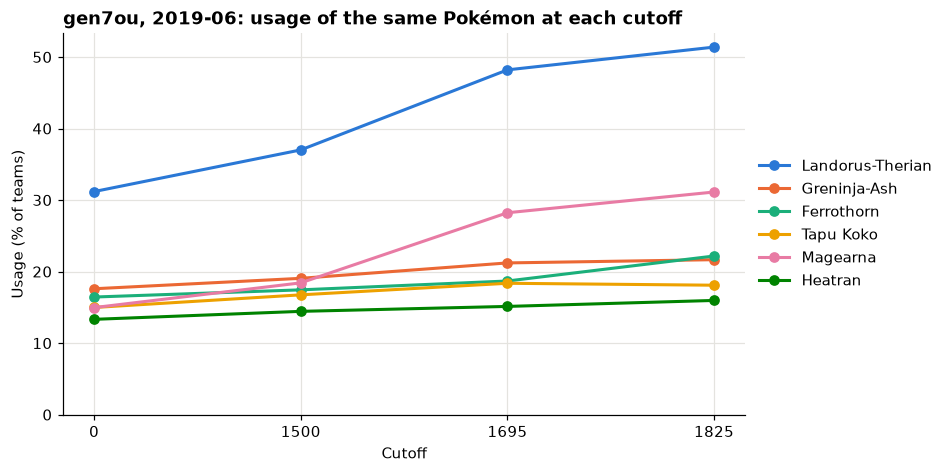

In [7]:
by_cutoff = (
    ss.load("usage", **ou_2019)
    .join(pokemon.lazy().select("pokemon_id", "name"), on="pokemon_id")
    .collect()
    .pivot(on="cutoff", index="name", values="usage_pct", sort_columns=True)
    .sort("0", descending=True)
    .head(6)
)
cutoff_labels = by_cutoff.columns[1:]

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, *usage_pcts in by_cutoff.iter_rows():
    ax.plot(cutoff_labels, usage_pcts, marker="o", label=name)
ax.set_title("gen7ou, 2019-06: usage of the same Pokémon at each cutoff")
ax.set_xlabel("Cutoff")
ax.set_ylabel("Usage (% of teams)")
ax.set_ylim(0)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

## Filter first, collect last

The detail tables are big: `spreads` and `teammates` have millions of rows per month. Counting them is free, since parquet stores the number of rows. Collecting them whole is not. Give `months`, `formats` and `cutoffs` to `ss.load`, add your own filter, and only then call `.collect()`: polars reads just the matching part of the files.

In [8]:
month_rows = ss.load("spreads", months=["2019-06"]).select(pl.len()).collect().item()

ou_1695 = {**ou_2019, "cutoffs": [1695]}
landorus_spreads = ss.load("spreads", **ou_1695).filter(pl.col("pokemon_id") == "landorustherian").collect()
print(f"spreads, 2019-06: {month_rows:,} rows in the month, {landorus_spreads.height:,} collected")

spreads, 2019-06: 7,755,608 rows in the month, 12,324 collected


## From weights to percentages

Where the Lite has a ready-made `pct`, the Complete keeps Smogon's raw `weight`: the weighted number of the Pokémon's sets that have this ability, item, move or spread. Every set has exactly one ability, so the sum of a Pokémon's ability weights in a file is its number of sets, and the denominator for all the other tables.

In [9]:
file_keys = ["month", "format", "cutoff", "pokemon_id"]
set_weights = ss.load("abilities", **ou_1695).group_by(file_keys).agg(pl.col("weight").sum().alias("sets")).collect()

(
    landorus_spreads.join(set_weights, on=file_keys)
    .with_columns((100 * pl.col("weight") / pl.col("sets")).cast(pl.Float64).round(2).alias("pct"))
    .sort("pct", descending=True)
    .select("nature", pl.col("^.*_ev$"), "pct")
    .head(6)
)

nature,hp_ev,atk_ev,def_ev,spa_ev,spd_ev,spe_ev,pct
"""Jolly""",0,252,0,0,4,252,18.63
"""Impish""",252,0,112,0,0,144,7.74
"""Jolly""",0,252,4,0,0,252,7.32
"""Jolly""",0,244,68,0,0,196,4.86
"""Jolly""",0,232,68,0,0,208,3.1
"""Naive""",0,252,0,4,0,252,2.78


## Teammates

`teammates` has two measures, never both on the same row. Until 2021-03 Smogon published an `association_score`: positive when the two Pokémon are teamed up more often than their usage predicts, negative when they avoid each other. From 2021-04 it publishes `count`, the weighted number of teams with both. Do not mix the two columns in one ranking.

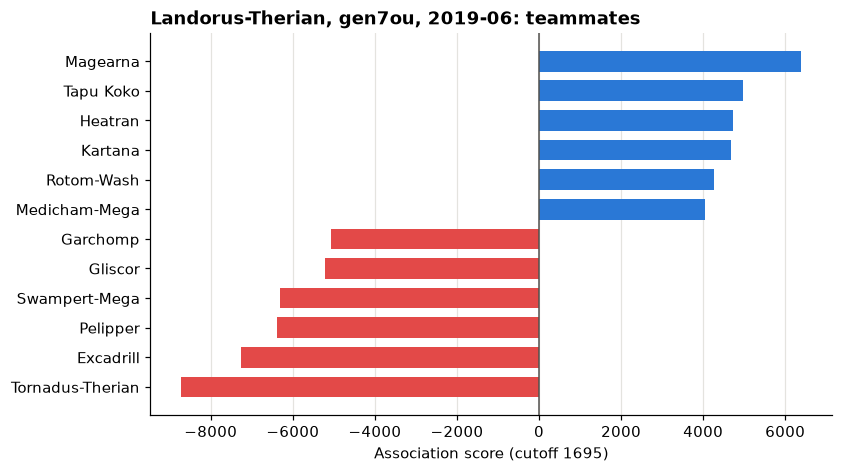

In [10]:
landorus_mates = (
    ss.load("teammates", **ou_1695)
    .filter(pl.col("pokemon_id") == "landorustherian")
    .join(pokemon.lazy().select(pl.col("pokemon_id").alias("teammate_id"), "name"), on="teammate_id")
    .sort("association_score", descending=True)
    .collect()
)
both_ends = pl.concat([landorus_mates.head(6), landorus_mates.tail(6)])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(both_ends["name"], both_ends["association_score"], height=0.7, color=["#2a78d6"] * 6 + ["#e34948"] * 6)
ax.invert_yaxis()
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_title("Landorus-Therian, gen7ou, 2019-06: teammates")
ax.set_xlabel("Association score (cutoff 1695)")
ax.grid(axis="y", visible=False)
plt.show()

## Checks and counters

One row per pair of opponents that met. `n` is the weighted number of encounters that ended with a knock-out or a switch, `p` the share of them where the Pokémon of the row was the one knocked out or forced out, `d` the standard error of `p`. Sorting on `p - 4 * d` keeps rare pairs from topping the list by luck.

In [11]:
(
    ss.load("checks_counters", **ou_1695)
    .filter(pl.col("pokemon_id") == "landorustherian")
    .join(pokemon.lazy().select(pl.col("pokemon_id").alias("opponent_id"), "name", "type1", "type2"), on="opponent_id")
    .with_columns((pl.col("p") - 4 * pl.col("d")).alias("score"))
    .sort("score", descending=True)
    .select(
        pl.col("name").alias("opponent"), "type1", "type2", pl.col("n").round(0), pl.col("p", "d", "score").round(3)
    )
    .head(8)
    .collect()
)

opponent,type1,type2,n,p,d,score
"""Cloyster""","""Water""","""Ice""",80.0,0.916,0.031,0.792
"""Mamoswine""","""Ice""","""Ground""",454.0,0.829,0.018,0.758
"""Kyurem""","""Dragon""","""Ice""",467.0,0.827,0.018,0.757
"""Kyurem-Black""","""Dragon""","""Ice""",1538.0,0.796,0.01,0.755
"""Latias-Mega""","""Dragon""","""Psychic""",1080.0,0.801,0.012,0.752
"""Skarmory""","""Steel""","""Flying""",1479.0,0.792,0.011,0.75
"""Kingdra""","""Water""","""Dragon""",243.0,0.842,0.023,0.749
"""Gyarados-Mega""","""Water""","""Dark""",1104.0,0.788,0.012,0.738


## Where to go from here

- The other tables work the same way: `leads`, `movesets` (how highly rated the players using each Pokémon are), `metagame_styles`, `stalliness`, `happiness`, and `mega` for 2014-11 to 2015-10. `items`, `moves` and `tera_types` carry a `weight` like `spreads`.
- Give `years` or `months` to `ss.load`, not both, and prefer a short list: without either it fetches every year since 2014.
- If the 18 most played series at their standard cutoff are enough, the Lite dataset is one small file per table, with percentages already computed: `ss.load_lite("usage")`.

Source: [smogon.com/stats](https://www.smogon.com/stats/); Pokémon names, types and base stats come from [Pokémon Showdown](https://github.com/smogon/pokemon-showdown).